# Online Shoppers: binary classification
Compare validation-tuned XGBoost and LightGBM with frozen TabPFN-3.5-Fast and Mitra v2. The outcome is **Revenue** (purchase: `True`). Each model uses the same fixed stratified train/validation/test split. The primary metric is **ROC-AUC**; average precision, F1, precision, recall, and accuracy provide context for class imbalance.

Source: [UCI Online Shoppers Purchasing Intention](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset), Sakar and Kastro (2018), [DOI](https://doi.org/10.24432/C5F88Q), **CC BY 4.0**. The released data contain 12,330 sessions, 17 predictors, and 1,908 purchases. Download and CSV checksums are pinned in the dataset manifest.

In [1]:
from pathlib import Path
import os
import sys

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "src/benchmark.py").exists())
sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from src.benchmark import save_results
from src.data import make_split, RANDOM_STATE
from src.datasets import load_online_shoppers
from src.evaluation import comparison_table
from src.experiments import run_isolated_comparison
from src.features import ShopperFeatures
from src.models.classical import make_classical_models, classical_search_spaces
from src.models.tabpfn import make_tabpfn_models
from src.models.mitra import make_mitra_models
from src.plotting import plot_comparison
from src.preprocessing import make_preprocessor

SEED = RANDOM_STATE
PROFILE = os.environ.get("BENCHMARK_PROFILE", "full")  # full or smoke
DEVICE = os.environ.get("BENCHMARK_DEVICE", "auto")  # CUDA for full foundation-model runs
MODEL_TIMEOUT = float(os.environ.get("BENCHMARK_MODEL_TIMEOUT", "300"))
DOWNLOAD_DATA = True
DOWNLOAD_WEIGHTS = False  # Pre-cache pinned weights; see docs/online-shoppers.md.
assert PROFILE in {"full", "smoke"}
OUTPUT = ROOT / "results/online-shoppers" / PROFILE
OUTPUT.mkdir(parents=True, exist_ok=True)
print(f"Profile={PROFILE}; device={DEVICE}; per-model budget={MODEL_TIMEOUT:g}s; seed={SEED}")

Profile=full; device=cuda; per-model budget=300s; seed=42


## Load and validate the source
The loader verifies both archive and CSV hashes, row/column counts, missing values, and target counts. `Revenue` is removed from predictors. Month, visitor type, weekend, and the operating-system/browser/region/traffic identifiers are categorical inputs. No rows are dropped or deduplicated in the full profile.

The **smoke** profile is an explicitly labeled 500-row stratified sample for checking notebook execution. It writes to a separate directory and must not be presented as the full benchmark.

In [2]:
X, y, source = load_online_shoppers(download=DOWNLOAD_DATA)
if PROFILE == "smoke":
    selected, _ = train_test_split(np.arange(len(y)), train_size=500, stratify=y, random_state=SEED)
    selected = np.sort(selected)
    X, y = X.iloc[selected].copy(), y.iloc[selected].copy()

splits = make_split(y.to_numpy(), "binary", SEED)
split_record = {key: positions.tolist() for key, positions in splits.items()}
(OUTPUT / "splits.json").write_text(json.dumps({"seed": SEED, "profile": PROFILE,
    "source_row_positions": X.index.tolist(), "splits": split_record}, indent=2) + "\n")
display(pd.DataFrame([{"partition": key, "rows": len(positions),
    "purchases": int(y.iloc[positions].sum()), "purchase_fraction": float(y.iloc[positions].mean())}
    for key, positions in splits.items()]).set_index("partition"))
print(f"Predictors: {X.shape[1]}; source identical full rows: {source['identical_full_rows']}; excluded target: Revenue")
print("Archive SHA-256:", source["archive_sha256"])
print("CSV SHA-256:", source["csv_sha256"])
assert "Revenue" not in X.columns

,rows,purchases,purchase_fraction
partition,,,
train,7398,1145,0.154772
validation,2466,381,0.154501
test,2466,382,0.154907


Predictors: 17; source identical full rows: 125; excluded target: Revenue
Archive SHA-256: 2972e6184d3ad7beaaa831d9fc2b059dc3ee29df69d1ec593c466a5cd8485d14
CSV SHA-256: b3055ee355f59134d851d32641183cb4a8b45def7124d2f50442a042f358e0d9


## Training-data exploration
Explore only training features when preparing the experiment. The class counts above describe the fixed split; no test metric is used for model or feature selection. The source contains 125 identical full rows. They are retained to preserve the released dataset; row positions are disjoint, but distinct sessions with identical feature values cannot be distinguished further without identifiers.

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend
7516,0,0.0,0,0.0,24,607.966667,0.000000,0.004167,19.474658,0.0,Nov,4,1,1,2,New_Visitor,False
10519,1,14.0,0,0.0,14,988.062500,0.014286,0.028571,68.849057,0.0,Dec,2,5,9,1,Returning_Visitor,False
6588,3,35.2,0,0.0,44,1535.666667,0.012766,0.014184,17.210226,0.0,Jul,1,1,1,3,Returning_Visitor,False
490,0,0.0,0,0.0,7,289.500000,0.000000,0.014286,0.000000,0.0,Mar,1,1,1,1,Returning_Visitor,True
7800,0,0.0,0,0.0,41,3389.800000,0.032479,0.050194,0.000000,0.0,Sep,2,4,3,1,Returning_Visitor,False


,dtype,missing,unique_training_values
Administrative,int64,0,24
Administrative_Duration,float64,0,2241
Informational,int64,0,17
Informational_Duration,float64,0,863
ProductRelated,int64,0,259
ProductRelated_Duration,float64,0,5986
BounceRates,float64,0,1260
ExitRates,float64,0,3104
PageValues,float64,0,1619
SpecialDay,float64,0,6


,count,mean,std,min,25%,50%,75%,max
Administrative,7398.0,2.330630,3.337921,0.0,0.000000,1.000000,4.000000,24.000000
Administrative_Duration,7398.0,80.583697,179.744057,0.0,0.000000,8.000000,92.000000,3398.750000
Informational,7398.0,0.494728,1.259883,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,7398.0,34.560210,144.167281,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,7398.0,31.265883,42.832401,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,7398.0,1177.064599,1912.856017,0.0,183.541667,597.125000,1450.841355,63973.522230
BounceRates,7398.0,0.022079,0.048568,0.0,0.000000,0.002899,0.016667,0.200000
ExitRates,7398.0,0.043001,0.048694,0.0,0.014286,0.025000,0.050000,0.200000
PageValues,7398.0,5.996203,18.786550,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,7398.0,0.062206,0.200275,0.0,0.000000,0.000000,0.000000,1.000000


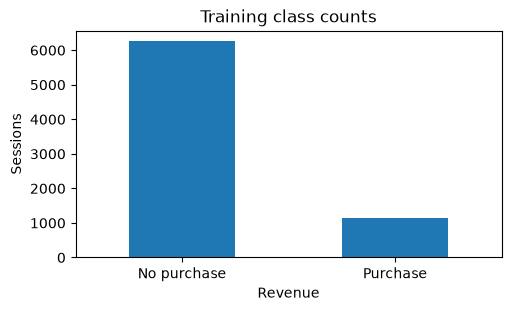

In [3]:
training = X.iloc[splits["train"]]
display(training.head())
display(pd.DataFrame({"dtype": training.dtypes.astype(str), "missing": training.isna().sum(),
    "unique_training_values": training.nunique()}))
display(training.select_dtypes("number").describe().T)
fig, axis = plt.subplots(figsize=(5, 3), layout="constrained")
y.iloc[splits["train"]].value_counts().rename(index={False: "No purchase", True: "Purchase"}).plot.bar(ax=axis, rot=0)
axis.set(title="Training class counts", ylabel="Sessions")
plt.show()

## Predeclared feature and model settings
Raw foundation-model runs use the 17 original predictors with model-required encoding/preprocessing. The engineered setting keeps those predictors and adds five label-free, row-local features: total pages, total duration, seconds per page, product-page fraction, and exit-rate minus bounce-rate. Zero-page ratios are set to zero. These features are fixed before evaluation and fit no population statistics.

Both classical models use that engineered setting with train-only imputation, encoding, and scaling. Each receives the existing four-candidate, 80-tree validation search. Foundation models use pinned frozen weights with no validation tuning, calibration, or threshold optimization. TabPFN uses its checkpoint's auto ensemble; Mitra uses one estimator. All models retain the same training observations. The dummy baseline predicts the training prior.

In [4]:
models = {"Dummy prior": DummyClassifier(strategy="prior", random_state=SEED)}
models.update(make_classical_models("binary", SEED))
models.update(make_tabpfn_models("binary", SEED, DEVICE, download=DOWNLOAD_WEIGHTS))
models.update(make_mitra_models("binary", SEED, DEVICE, download=DOWNLOAD_WEIGHTS))
models["TabPFN - Engineered"] = make_tabpfn_models("binary", SEED, DEVICE, download=DOWNLOAD_WEIGHTS)["TabPFN - Raw"]
models["Mitra v2 - Engineered"] = make_mitra_models("binary", SEED, DEVICE, download=DOWNLOAD_WEIGHTS)["Mitra v2 - Raw"]

# Choosing column names from a transformed training frame learns no holdout information.
engineered_training = ShopperFeatures().fit_transform(training)
classical_preprocessor = Pipeline([
    ("features", ShopperFeatures()), ("encoding", make_preprocessor(engineered_training)),
])
preprocessors = {name: classical_preprocessor for name in ("XGBoost", "LightGBM")}
preprocessors.update({name: ShopperFeatures() for name in ("TabPFN - Engineered", "Mitra v2 - Engineered")})
search_spaces = classical_search_spaces()
for name, model in models.items():
    print(name, "— validation grid" if name in search_spaces else "— fixed inference")

Dummy prior — fixed inference
XGBoost — validation grid
LightGBM — validation grid
TabPFN - Raw — fixed inference
Mitra v2 - Raw — fixed inference
TabPFN - Engineered — fixed inference
Mitra v2 - Engineered — fixed inference


## Execute the comparison
Each independent, predeclared recipe runs in its own process to release model/GPU memory on exit. Selection uses training and validation only; the selected model is then scored on the test partition. Earlier test scores do not alter later recipes. The timeout includes loading, tuning, and prediction. A model that exceeds the budget or available memory is **Not evaluated**, with a reason and no metric values. Inputs are never silently subsampled to make a model run. Unexpected implementation failures remain distinct and fail the notebook after diagnostic artifacts are saved.

In [5]:
results = run_isolated_comparison(
    X, y, models, task="binary", dataset_name=f"Online Shoppers ({PROFILE}, {len(X):,} rows)",
    seed=SEED, splits=splits, positive_label=True, search_spaces=search_spaces,
    preprocessors=preprocessors, timeout=MODEL_TIMEOUT, output_path=OUTPUT / "results.json",
)
results["dataset"].update({"profile": PROFILE, "source": source, "source_row_positions": X.index.tolist()})
results["checkpoint_manifest"] = json.loads((ROOT / "checkpoints/manifest.json").read_text())
results["feature_engineering"] = {"added": list(ShopperFeatures.added),
    "classical_setting": "engineered", "foundation_settings": ["raw", "engineered"],
    "zero_page_ratios": 0, "threshold_selection": "none; model default"}
save_results(results, OUTPUT / "results.json")

Running Dummy prior...


Dummy prior: evaluated


Running XGBoost...


XGBoost: evaluated


Running LightGBM...


...

Mitra v2 - Raw: evaluated


Running TabPFN - Engineered...


TabPFN - Engineered: evaluated


Running Mitra v2 - Engineered...


Mitra v2 - Engineered: evaluated


## Final evaluation table
Metrics below are calculated from saved test predictions. Average precision summarizes the precision-recall ranking; it is not trapezoidal PR-curve area. Default classification decisions determine F1, precision, and recall. Accuracy alone is insufficient for the imbalanced target. Empty metrics denote an unevaluated model, not a zero score.

In [6]:
status = pd.DataFrame([{"model": row["name"],
    "status": "Evaluated" if row["status"] == "evaluated" else "Not evaluated" if row["status"] == "unavailable" else "Failed",
    "reason": row.get("reason", ""), "seconds": row["elapsed_seconds"]} for row in results["models"]]).set_index("model")
table = comparison_table(results)
export = table.join(status)
export.to_csv(OUTPUT / "metrics.csv")
display(export.style.format({column: "{:.4f}" for column in table.columns}, na_rep="Not evaluated"))
print("Profile:", PROFILE, "—", "full released dataset" if PROFILE == "full" else "SMOKE SAMPLE; not full benchmark results")

,roc_auc,average_precision,f1,precision,recall,accuracy,status,reason,seconds
model,,,,,,,,,
Dummy prior,0.5000,0.1549,0.0000,0.0000,0.0000,0.8451,Evaluated,,2.805464
XGBoost,0.9294,0.7341,0.6515,0.7134,0.5995,0.9006,Evaluated,,3.957991
LightGBM,0.9321,0.7396,0.6420,0.7019,0.5916,0.8978,Evaluated,,3.234766
TabPFN - Raw,0.9350,0.7593,0.6695,0.7382,0.6126,0.9063,Evaluated,,19.353293
Mitra v2 - Raw,0.9366,0.7543,0.6341,0.7304,0.5602,0.8998,Evaluated,,168.584553
TabPFN - Engineered,0.9348,0.7570,0.6705,0.7405,0.6126,0.9067,Evaluated,,19.908928
Mitra v2 - Engineered,0.9353,0.7514,0.6489,0.7474,0.5733,0.9039,Evaluated,,206.599728


Profile: full — full released dataset


## Comparison plots
The first plot compares the primary metric, ROC-AUC. The second shows average precision. Only evaluated models are plotted; all attempted models and limitations remain in the table above.

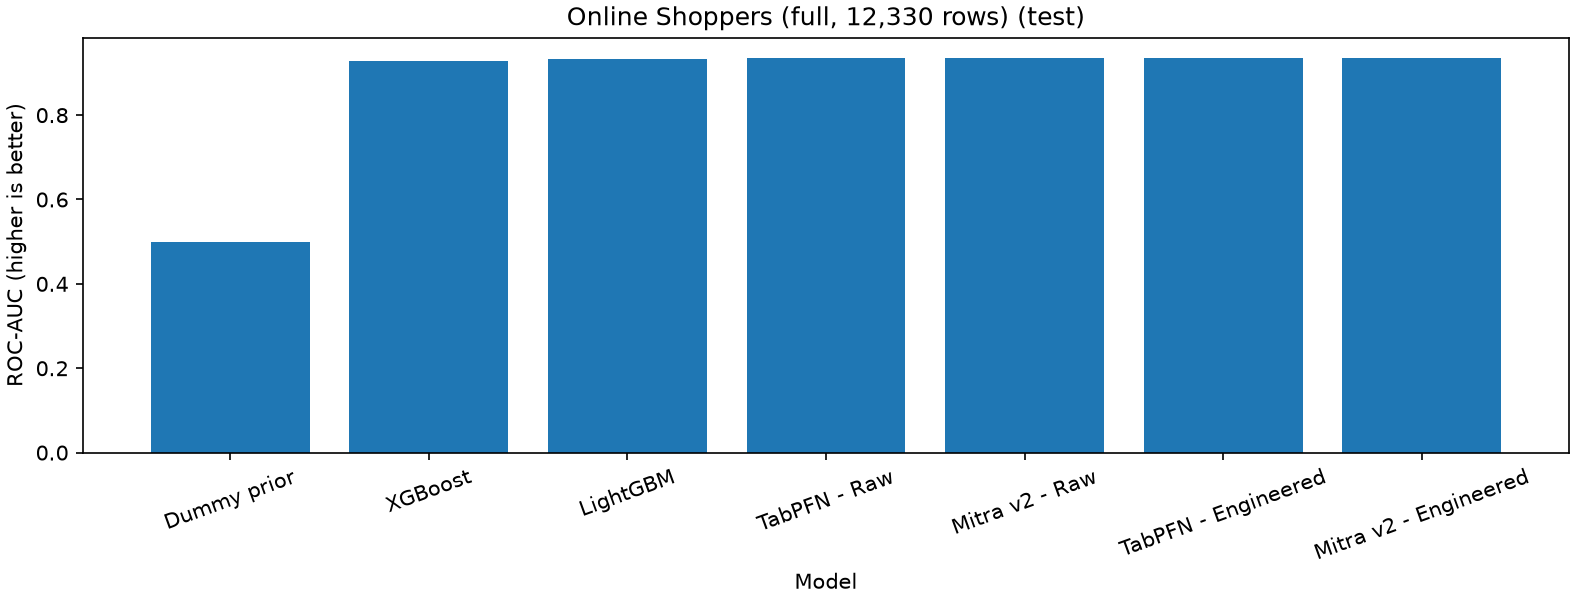

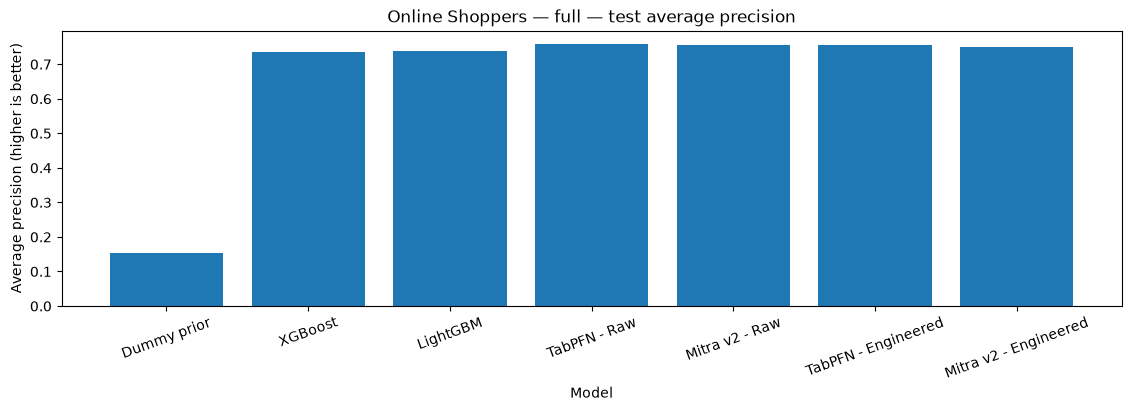

In [7]:
figure = plot_comparison(results)
figure.savefig(OUTPUT / "roc_auc.png", dpi=150)
plt.show()

available = table.dropna(subset=["average_precision"])
figure, axis = plt.subplots(figsize=(max(6, 1.6 * len(available)), 4), layout="constrained")
axis.bar(available.index, available["average_precision"])
axis.set(ylabel="Average precision (higher is better)", xlabel="Model",
    title=f"Online Shoppers — {PROFILE} — test average precision")
axis.tick_params(axis="x", labelrotation=20)
figure.savefig(OUTPUT / "average_precision.png", dpi=150)
plt.show()

## Observations and limitations
This is a single-split, retrospective comparison on the released dataset. It does not establish statistical significance, general model superiority, causal effects, or live purchasing-intention performance. Session-derived fields such as `PageValues` are included as released; their availability at a particular live prediction time is not verified. Identical released rows and unavailable session identifiers limit independence checks. No test-based feature/threshold tuning, resampling, or train-plus-validation refit is performed.

The saved artifact includes split and source-row positions, checksums, feature recipes, selected settings, candidate validation scores, predictions, package versions, checkpoint hashes, device details for evaluated foundation models, and explicit runtime limitations.

In [8]:
ranked = table["roc_auc"].dropna().sort_values(ascending=False)
if not ranked.empty:
    display(Markdown(f"Highest observed test ROC-AUC: **{ranked.index[0]}**, **{ranked.iloc[0]:.4f}** ({PROFILE} profile)."))
not_evaluated = status[status["status"] != "Evaluated"]
if not not_evaluated.empty:
    display(not_evaluated[["status", "reason"]])
print("Artifacts:", OUTPUT.relative_to(ROOT))
failed = [row["name"] for row in results["models"] if row["status"] == "failed"]
assert not failed, f"Unexpected model failures require investigation: {failed}"

Highest observed test ROC-AUC: **Mitra v2 - Raw**, **0.9366** (full profile).

Artifacts: results/online-shoppers/full
